# Book Market Analytics — Books to Scrape
**Data Science 500 — end-to-end project.** The notebook follows the five steps of data science from the study guide:

1. **Step 1 – Asking an interesting question** (this cell)
2. **Step 2 – Obtaining the data:** web scraping with `requests` and BeautifulSoup
3. **Step 3 – Exploring the data:** cleaning, preparing and visualising the data
4. **Step 4 – Modelling the data:** linear regression
5. **Step 5 – Communicating and visualising results:** a short written report (PDF)

## Step 1: Asking an interesting question
**Business question:** *Which publicly visible book attributes (rating, genre, stock level, title and description features) are associated with a book's price, and can a linear regression predict price from them?*

**Why it matters:** a bookstore or publisher that sets list prices wants to know whether ratings, genre, stock levels or text features carry any information about price, or whether price is driven by things the catalogue does not show.

**Running the notebook:** *Restart & Run All* creates `books_raw.csv`, `books_clean.csv`, `model_results.csv` and `Book_Market_Analytics_Report.pdf` in the notebook's folder. Scraping all 1 000 book pages one at a time takes roughly 5–10 minutes on a fast connection and longer on a slow one.

## 1. Setup

In [1]:
# Import the libraries we need
import os
import time
import tempfile
import subprocess
import sys
from datetime import date
from pathlib import Path
from urllib.parse import urljoin     # joins a page address and a relative link

import requests                      # grabs web pages
from bs4 import BeautifulSoup        # reads (parses) HTML

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor        # a 'model' that always predicts the average
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# Shown on the report cover page
STUDENT_NAME = "Fulufhelo Mulaudzi"
STUDENT_NUMBER = "402601594"

# My conclusion for retailers and publishers (printed in the report under "6. Conclusion")
PERSONAL_CONCLUSION = (
    "The results show that on this sandbox site, star rating and stock level "
    "do not meaningfully predict book price (R² close to zero). For a retailer, "
    "this means pricing decisions should be based on supplier cost, margin targets "
    "and competitor prices rather than customer ratings. Publishers should not "
    "assume that a highly-rated title can command a higher list price without "
    "further evidence from a real market."
)

# Scraping settings (leave the defaults for the real site)
SITE = os.environ.get("BOOKS_BASE_URL", "https://books.toscrape.com")
DELAY = float(os.environ.get("BOOKS_DELAY", "0.1"))     # pause between requests (be polite)    # pause between requests (be polite)
HEADERS = {"User-Agent": "StudentProject/1.0 (educational scraping; Data Science 500)"}

OUT_DIR = Path.cwd()                                     # files are saved in the notebook's folder
pd.set_option("display.max_columns", None)
print("Libraries loaded. Output folder:", OUT_DIR)

Libraries loaded. Output folder: c:\Users\HP\Downloads\BookAnalytics_Assignment_Simple\BookAnalytics_Assignment


## Step 2: Obtaining the Data (Web Scraping with BeautifulSoup)

**Approach.** The listing pages of Books to Scrape only show the *title, price, star rating and "In stock"*. The **stock quantity** (e.g. "22 available"), **genre**, **description** and **UPC** are only on each book's own page. So the scraper works in two stages:

1. **Listing pages** — loop through all 50 pages (20 books each) and collect the title, price, rating word, availability text and the link to each book's page.
2. **Book pages** — loop through the 1 000 links and collect the stock quantity, genre, description, UPC and number of reviews.

**Good practice used:** a User-Agent header, a short delay between requests, error handling with `try/except`, and `response.encoding = "utf-8"` so the `£` sign is read correctly.

In [2]:
# Stage 1: scrape the 50 listing pages
all_books = []                                            # one dictionary per book will go in here

for page in range(1, 51):                                 # pages 1 to 50
    url = SITE + "/catalogue/page-" + str(page) + ".html"
    try:
        response = requests.get(url, headers=HEADERS, timeout=20)
        response.raise_for_status()
    except requests.RequestException as e:
        print("Page", page, "failed:", e)
        continue

    response.encoding = "utf-8"                           # makes the "£" sign read correctly
    soup = BeautifulSoup(response.text, "html.parser")
    articles = soup.select("article.product_pod")         # every book on the page

    for article in articles:
        link = article.select_one("h3 a")
        book = {
            "title": link["title"],
            "price_raw": article.select_one("p.price_color").text.strip(),
            "rating_word": article.select_one("p.star-rating")["class"][1],
            "detail_url": urljoin(url, link["href"]),
            "page": page,
        }
        all_books.append(book)

    if page == 1 or page % 10 == 0:
        print("Listing page", page, "of 50 done - books so far:", len(all_books))
    time.sleep(DELAY)

print("Stage 1 complete. Books found:", len(all_books))

Listing page 1 of 50 done - books so far: 20
Listing page 10 of 50 done - books so far: 200
Listing page 20 of 50 done - books so far: 400
Listing page 30 of 50 done - books so far: 600
Listing page 40 of 50 done - books so far: 800
Listing page 50 of 50 done - books so far: 1000
Stage 1 complete. Books found: 1000


In [3]:
# Stage 2: visit every book's own page for stock quantity, genre, description and UPC
# NOTE: this stage visits all 1,000 book pages one at a time, with a 0.25-second polite delay
# between requests. The run time depends on the internet connection (about 5-10 minutes on a fast one).
failed = 0
session = requests.Session()          # reuses one connection, which is faster

for i in range(len(all_books)):
    book = all_books[i]
    try:
        response = session.get(book["detail_url"], headers=HEADERS, timeout=20)
        response.raise_for_status()
        response.encoding = "utf-8"
        soup = BeautifulSoup(response.text, "html.parser")

        # genre is the 3rd item in the breadcrumb: Home > Books > Genre > Title
        crumbs = soup.find("ul", class_="breadcrumb").find_all("li")
        book["genre"] = crumbs[2].text.strip()

        # stock text, e.g. "In stock (22 available)"
        book["availability_raw"] = soup.find("p", class_="availability").text.strip()

        # description (a few books have none)
        desc_header = soup.find("div", id="product_description")
        if desc_header is not None:
            book["description"] = desc_header.find_next_sibling("p").text.strip()
        else:
            book["description"] = None

        # the product table: UPC is the 1st value, number of reviews is the 7th
        cells = soup.find("table").find_all("td")
        book["upc"] = cells[0].text.strip()
        book["num_reviews_raw"] = cells[6].text.strip()
    except Exception as e:
        failed = failed + 1                               # keep going if one page fails
        print("Book page failed:", book["title"], "-", e)

    if (i + 1) % 100 == 0:
        print("Book pages scraped:", i + 1, "of", len(all_books))
    time.sleep(DELAY)

print("DONE. Books scraped:", len(all_books), "| failed book pages:", failed)

# Summary of scraping quality (used in the report)
if failed == 0:
    print("Scrape summary: all", len(all_books), "book pages scraped successfully with no failures.")
else:
    print("Scrape summary:", len(all_books) - failed, "succeeded,", failed, "failed.")
    if failed / len(all_books) > 0.05:
        print("WARNING: more than 5% of pages failed. Consider running the notebook again.")

assert len(all_books) >= 200, "Fewer than 200 books scraped - check your internet and run again."

Book pages scraped: 100 of 1000
Book pages scraped: 200 of 1000
Book pages scraped: 300 of 1000
Book pages scraped: 400 of 1000
Book pages scraped: 500 of 1000
Book pages scraped: 600 of 1000
Book pages scraped: 700 of 1000
Book pages scraped: 800 of 1000
Book pages scraped: 900 of 1000
Book pages scraped: 1000 of 1000
DONE. Books scraped: 1000 | failed book pages: 0
Scrape summary: all 1000 book pages scraped successfully with no failures.


In [4]:
# Build the raw DataFrame and save it
df = pd.DataFrame(all_books)
df.to_csv(OUT_DIR / "books_raw.csv", index=False)
print("Raw data shape:", df.shape)
df.head()

Raw data shape: (1000, 10)


,title,price_raw,rating_word,detail_url,page,genre,availability_raw,description,upc,num_reviews_raw
0,A Light in the Attic,£51.77,Three,https://books.toscrape.com/catalogue/a-light-i...,1,Poetry,In stock (22 available),It's hard to imagine a world without A Light i...,a897fe39b1053632,0
1,Tipping the Velvet,£53.74,One,https://books.toscrape.com/catalogue/tipping-t...,1,Historical Fiction,In stock (20 available),"""Erotic and absorbing...Written with starling ...",90fa61229261140a,0
2,Soumission,£50.10,One,https://books.toscrape.com/catalogue/soumissio...,1,Fiction,In stock (20 available),"Dans une France assez proche de la nôtre, un h...",6957f44c3847a760,0
3,Sharp Objects,£47.82,Four,https://books.toscrape.com/catalogue/sharp-obj...,1,Mystery,In stock (20 available),"WICKED above her hipbone, GIRL across her hear...",e00eb4fd7b871a48,0
4,Sapiens: A Brief History of Humankind,£54.23,Five,https://books.toscrape.com/catalogue/sapiens-a...,1,History,In stock (20 available),From a renowned historian comes a groundbreaki...,4165285e1663650f,0


## Step 3: Exploring the Data — Cleaning & Preparation

Every cleaning decision is listed below with the reason for it.

- **Price (`price_raw`, e.g. `"£51.77"`):** this is text with a currency symbol, so it can't be used in calculations. I removed the `£` sign and converted the text to a `float`.

- **Rating (`rating_word`, e.g. `"Three"`):** the site gives the rating as a word. I mapped One to Five onto 1 to 5. Ratings are ordinal, but treating them as numeric 1 to 5 lets them be used in plots and in the regression.

- **Availability (`availability_raw`, e.g. `"In stock (22 available)"`):** the quantity is buried inside text. I pulled out the number as `stock_quantity` and created a 0/1 `in_stock` flag. If a book is in stock with no number shown, it is recorded as 1.

- **Genre:** I stripped stray whitespace and kept it as a categorical variable. It acts as the site's tag for each book and is converted to 0/1 columns for modelling.

- **Description:** this is free text, and a few books have none. I replaced missing descriptions with an empty string instead of dropping those rows, because their price and rating are still valid. A `has_description` flag records which books had one, and `description_length` and `description_word_count` capture the text as numbers.

- **UPC:** each product should have a unique UPC, so I used it to find and drop duplicate products. This stops any book being counted twice and distorting the statistics.

- **Title:** I derived `title_length` and `title_word_count` to turn the text into numeric features.

Rows are dropped only when a critical field (price, rating or genre) is missing. Dropping rows over a missing description would throw away good pricing data.

In [5]:
# Clean the price: "£51.77" -> 51.77
# The "Â" is an encoding artefact from the site (it appears when UTF-8 is mis-read as Latin-1);
# removing it here keeps the conversion robust even if a reader's environment decodes differently.
df["price"] = df["price_raw"].str.replace("Â", "").str.replace("£", "").astype(float)

# Clean the rating: "Three" -> 3
# The site gives ratings as words; ratings are ordinal, but mapping to 1-5 lets us use them
# in plots and in the regression without a separate encoding step.
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
df["rating"] = df["rating_word"].map(rating_map)

# Clean the stock: "In stock (22 available)" -> 22
# The number is buried in the text; string splitting is simpler and safer than regex for this fixed format.
# If a book is in stock but shows no number, we record 1 so it still counts as available.
def get_stock(text):
    if isinstance(text, str) and "(" in text:
        return int(text.split("(")[1].split(" ")[0])      # the number after the "("
    if isinstance(text, str) and "In stock" in text:
        return 1                                          # in stock but no number shown
    return 0

df["stock_quantity"] = df["availability_raw"].apply(get_stock)
df["in_stock"] = df["availability_raw"].str.contains("In stock").astype(int)

# Clean genre and number of reviews
# Genre should be a clean category for grouping and one-hot encoding later.
# Reviews are numeric in the HTML; errors="coerce" safely converts bad text to 0.
df["genre"] = df["genre"].str.strip()
df["num_reviews"] = pd.to_numeric(df["num_reviews_raw"], errors="coerce").fillna(0).astype(int)

print("Missing ratings:", df["rating"].isnull().sum())
print("Missing genres:", df["genre"].isnull().sum())
print("Missing descriptions:", df["description"].isnull().sum())

Missing ratings: 0
Missing genres: 0
Missing descriptions: 2


In [6]:
# Description: fill missing with "" and make number features from the text
# Keeping rows with no description (rather than dropping them) preserves valid price and rating
# information; the has_description flag lets the model learn that "no description" is itself a signal.
missing_desc_raw = df["description"].isnull().sum()       # count them BEFORE filling, for the cleaning log
df["description"] = df["description"].fillna("")
df["has_description"] = (df["description"].str.len() > 0).astype(int)
df["description_length"] = df["description"].str.len()
df["description_word_count"] = df["description"].str.split().str.len()

# Title features
# Title length and word count are simple numeric proxies for how descriptive a title is.
df["title"] = df["title"].str.strip()
df["title_length"] = df["title"].str.len()
df["title_word_count"] = df["title"].str.split().str.len()

# ----------------------------------------------------------------
# CLEANING LOG — shows exactly what is dropped and why
# ----------------------------------------------------------------
raw_shape = pd.read_csv(OUT_DIR / "books_raw.csv").shape
rows_before = len(df)

print("=" * 60)
print("CLEANING LOG")
print("=" * 60)
print("Raw dataset (books_raw.csv):")
print("  Rows:", raw_shape[0], "| Columns:", raw_shape[1])
print()
print("Data quality BEFORE cleaning:")
print("  Rows missing price:        ", df["price"].isnull().sum())
print("  Rows missing rating:       ", df["rating"].isnull().sum())
print("  Rows missing genre:        ", df["genre"].isnull().sum())
print("  Rows missing description:  ", missing_desc_raw, "(kept, filled with empty text)")
print("  Duplicated UPCs:           ", df.duplicated(subset="upc").sum())
print()

# Duplicated UPCs are removed first because a repeated UPC means the same product was listed twice.
dups_removed = df.duplicated(subset="upc").sum()
df = df.drop_duplicates(subset="upc")

# Rows with missing price, rating or genre are dropped because they cannot be used for modelling.
rows_before_dropna = len(df)
df = df.dropna(subset=["price", "rating", "genre"])
dropna_removed = rows_before_dropna - len(df)

print("Data quality AFTER cleaning:")
print("  Duplicates removed (by UPC):  ", dups_removed)
print("  Rows removed (missing crit.): ", dropna_removed)
print("  Final rows in books_clean.csv:", len(df))
print()

# Keep only the final columns
df_clean = df[["upc", "title", "genre", "price", "rating", "in_stock", "stock_quantity",
               "num_reviews", "title_length", "title_word_count", "description",
               "description_length", "description_word_count", "has_description", "page"]]
df_clean = df_clean.reset_index(drop=True)

print("Clean dataset shape:", df_clean.shape)
print("Raw vs clean: rows", raw_shape[0], "->", df_clean.shape[0],
      "| columns", raw_shape[1], "->", df_clean.shape[1])
print("=" * 60)
print("\nMissing values in final dataset:\n", df_clean.isnull().sum())
print("\nData types:\n", df_clean.dtypes)
df_clean.head()

CLEANING LOG
Raw dataset (books_raw.csv):
  Rows: 1000 | Columns: 10

Data quality BEFORE cleaning:
  Rows missing price:         0
  Rows missing rating:        0
  Rows missing genre:         0
  Rows missing description:   2 (kept, filled with empty text)
  Duplicated UPCs:            0

Data quality AFTER cleaning:
  Duplicates removed (by UPC):   0
  Rows removed (missing crit.):  0
  Final rows in books_clean.csv: 1000

Clean dataset shape: (1000, 15)
Raw vs clean: rows 1000 -> 1000 | columns 10 -> 15

Missing values in final dataset:
 upc                       0
title                     0
genre                     0
price                     0
rating                    0
in_stock                  0
stock_quantity            0
num_reviews               0
title_length              0
title_word_count          0
description               0
description_length        0
description_word_count    0
has_description           0
page                      0
dtype: int64

Data types:
 upc  

,upc,title,genre,price,rating,in_stock,stock_quantity,num_reviews,title_length,title_word_count,description,description_length,description_word_count,has_description,page
0,a897fe39b1053632,A Light in the Attic,Poetry,51.77,3,1,22,0,20,5,It's hard to imagine a world without A Light i...,1017,164,1,1
1,90fa61229261140a,Tipping the Velvet,Historical Fiction,53.74,1,1,20,0,18,3,"""Erotic and absorbing...Written with starling ...",1029,165,1,1
2,6957f44c3847a760,Soumission,Fiction,50.10,1,1,20,0,10,1,"Dans une France assez proche de la nôtre, un h...",1093,163,1,1
3,e00eb4fd7b871a48,Sharp Objects,Mystery,47.82,4,1,20,0,13,2,"WICKED above her hipbone, GIRL across her hear...",1635,274,1,1
4,4165285e1663650f,Sapiens: A Brief History of Humankind,History,54.23,5,1,20,0,37,6,From a renowned historian comes a groundbreaki...,1945,304,1,1


In [7]:
# Save the final dataset (Deliverable 2)
df_clean.to_csv(OUT_DIR / "books_clean.csv", index=False)
print("Saved books_clean.csv:", df_clean.shape)

# Text preparation: count the most common words in the descriptions
stop_words = ["the", "and", "that", "with", "for", "from", "this", "are", "was", "were", "has", "have",
              "her", "his", "their", "they", "them", "she", "but", "not", "who", "will", "can", "all",
              "more", "one", "about", "into", "out", "when", "what", "than", "then", "been", "also",
              "which", "its", "you", "your", "our", "after", "before", "while", "over", "only"]
word_counts = {}
for text in df_clean["description"]:
    for word in text.lower().split():
        word = word.strip(".,;:!?\"'()-")                  # remove punctuation at the ends
        if len(word) > 3 and word not in stop_words:
            word_counts[word] = word_counts.get(word, 0) + 1

top_words = pd.Series(word_counts).sort_values(ascending=False).head(15)
top_words.head(10)

Saved books_clean.csv: (1000, 15)


life     723
world    561
book     520
love     488
most     465
time     414
story    400
years    387
first    382
just     358
dtype: int64

## Step 3 (continued): Exploring the Data — Visualisation

In [8]:
# Descriptive statistics
price_skew = df_clean["price"].skew()
print("--- PRICE DESCRIPTIVE STATISTICS ---")
print(df_clean["price"].describe().round(2))
print("Skewness:", round(price_skew, 3))

print("\n--- PRICE BY STAR RATING ---")
print(df_clean.groupby("rating")["price"].agg(["mean", "median", "count"]).round(2))

# Genre statistics: number of books, average price, average rating
genre_stats = df_clean.groupby("genre")["price"].agg(["count", "mean"]).round(2)
genre_stats["avg_rating"] = df_clean.groupby("genre")["rating"].mean().round(2)
genre_stats.columns = ["books", "mean_price", "mean_rating"]
genre_stats = genre_stats.sort_values("books", ascending=False)
print("\n--- GENRES:", len(genre_stats), "genres, 10 largest ---")
print(genre_stats.head(10))

# Correlations with price
corr_stock = df_clean["price"].corr(df_clean["stock_quantity"])
corr_rating = df_clean["price"].corr(df_clean["rating"])
print("\nCorrelation price vs stock quantity:", round(corr_stock, 3))
print("Correlation price vs rating:", round(corr_rating, 3))

--- PRICE DESCRIPTIVE STATISTICS ---
count    1000.00
mean       35.07
std        14.45
min        10.00
25%        22.11
50%        35.98
75%        47.46
max        59.99
Name: price, dtype: float64
Skewness: -0.038

--- PRICE BY STAR RATING ---
         mean  median  count
rating                      
1       34.56   34.77    226
2       34.81   36.22    196
3       34.69   33.78    203
4       36.09   37.80    179
5       35.37   36.90    196

--- GENRES: 50 genres, 10 largest ---
                books  mean_price  mean_rating
genre                                         
Default           152       34.39         2.84
Nonfiction        110       34.26         2.88
Sequential Art     75       34.57         2.97
Add a comment      67       35.80         2.76
Fiction            65       36.07         3.18
Young Adult        54       35.45         3.30
Fantasy            48       39.59         3.08
Romance            35       33.93         2.63
Mystery            32       31.72       

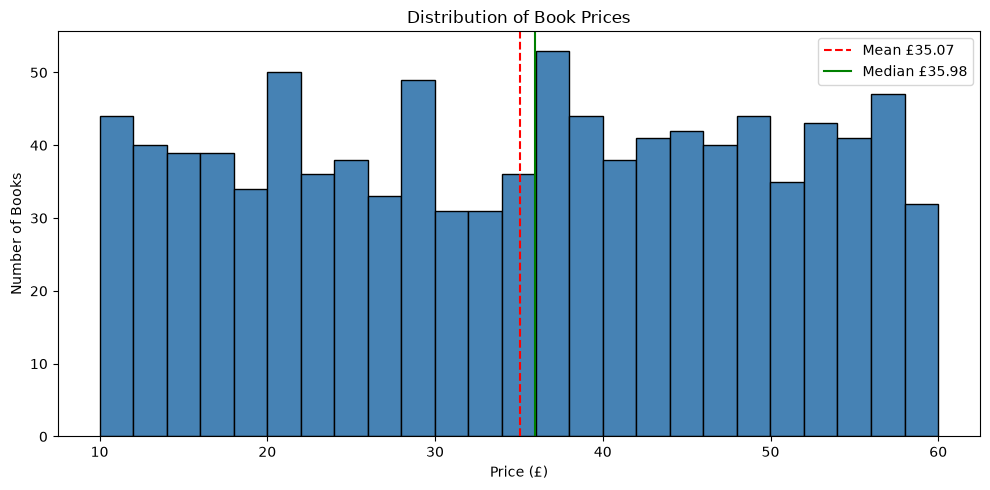

INTERPRETATION - price distribution
Prices range from £10.0 to £59.99 (mean £35.07, median £35.98).
The skewness is -0.04, so the distribution is approximately symmetric.
Prices are spread fairly evenly across the whole range, so the catalogue serves budget, mid-range and premium buyers alike.


In [9]:
# Plot 1: price distribution
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_clean["price"], bins=25, color="steelblue", edgecolor="black")
ax.axvline(df_clean["price"].mean(), color="red", linestyle="--", label="Mean £" + str(round(df_clean["price"].mean(), 2)))
ax.axvline(df_clean["price"].median(), color="green", linestyle="-", label="Median £" + str(round(df_clean["price"].median(), 2)))
ax.set_title("Distribution of Book Prices")
ax.set_xlabel("Price (£)")
ax.set_ylabel("Number of Books")
ax.legend()
plt.tight_layout()
plt.show()

# Interpretation (written from the real numbers)
p = df_clean["price"]
if abs(price_skew) < 0.3:
    shape = "approximately symmetric"
    meaning = "Prices are spread fairly evenly across the whole range, so the catalogue serves budget, mid-range and premium buyers alike."
elif price_skew > 0:
    shape = "right-skewed"
    meaning = "Most books are cheap with a smaller tail of premium titles, so the mean is pulled above the median."
else:
    shape = "left-skewed"
    meaning = "Most books are at the higher end with a tail of cheaper titles, so the mean is pulled below the median."
print("INTERPRETATION - price distribution")
print("Prices range from £" + str(round(p.min(), 2)) + " to £" + str(round(p.max(), 2)) +
      " (mean £" + str(round(p.mean(), 2)) + ", median £" + str(round(p.median(), 2)) + ").")
print("The skewness is " + str(round(price_skew, 2)) + ", so the distribution is " + shape + ".")
print(meaning)

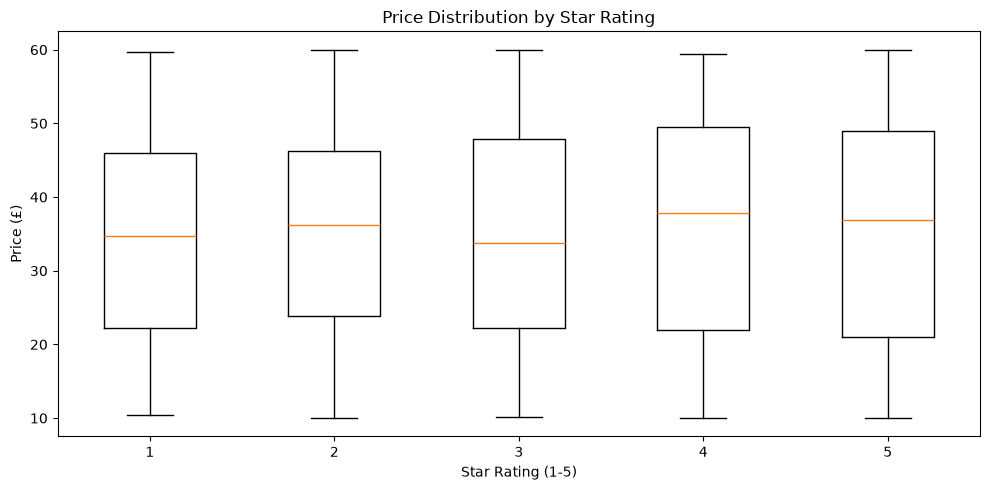

INTERPRETATION - price vs rating
Highest average price: 4-star books (£36.09)
Lowest average price: 1-star books (£34.56)
Correlation between rating and price: 0.028
Higher-rated books do NOT cost more: the boxes overlap and the correlation is close to zero.


In [10]:
# Plot 2: price by rating (box plot)
groups = []
for r in [1, 2, 3, 4, 5]:
    groups.append(df_clean[df_clean["rating"] == r]["price"])

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(groups)                                        # boxes are labelled 1 to 5
ax.set_title("Price Distribution by Star Rating")
ax.set_xlabel("Star Rating (1-5)")
ax.set_ylabel("Price (£)")
plt.tight_layout()
plt.show()

means = df_clean.groupby("rating")["price"].mean()
print("INTERPRETATION - price vs rating")
print("Highest average price: " + str(means.idxmax()) + "-star books (£" + str(round(means.max(), 2)) + ")")
print("Lowest average price: " + str(means.idxmin()) + "-star books (£" + str(round(means.min(), 2)) + ")")
print("Correlation between rating and price:", round(corr_rating, 3))
if abs(corr_rating) < 0.1:
    print("Higher-rated books do NOT cost more: the boxes overlap and the correlation is close to zero.")
elif corr_rating > 0:
    print("Higher-rated books tend to cost more.")
else:
    print("Higher-rated books tend to cost less.")

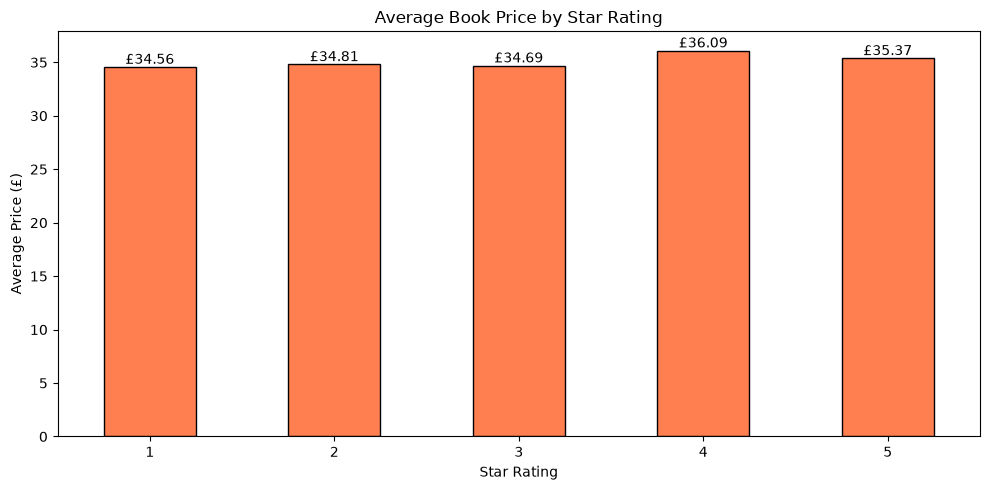

INTERPRETATION - average price by rating
Average price ranges from £34.56 (1-star books) to £36.09 (4-star books), a spread of £1.53 (4% of the overall mean price).
The averages are very close and show no consistent upward trend, so a higher rating does not come with a higher price (consistent with the box plot in Plot 2).


In [11]:
# Plot 3: average price by rating (bar chart)
avg_by_rating = df_clean.groupby("rating")["price"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
avg_by_rating.plot(kind="bar", color="coral", edgecolor="black", ax=ax)
ax.set_title("Average Book Price by Star Rating")
ax.set_xlabel("Star Rating")
ax.set_ylabel("Average Price (£)")
plt.xticks(rotation=0)
for i in range(len(avg_by_rating)):
    ax.text(i, avg_by_rating.values[i] + 0.3, "£" + str(round(avg_by_rating.values[i], 2)), ha="center")
plt.tight_layout()
plt.show()
# INTERPRETATION - Plot 3
spread = avg_by_rating.max() - avg_by_rating.min()
spread_pct = 100 * spread / df_clean["price"].mean()

print("INTERPRETATION - average price by rating")
print(f"Average price ranges from £{avg_by_rating.min():.2f} ({avg_by_rating.idxmin()}-star books) "
      f"to £{avg_by_rating.max():.2f} ({avg_by_rating.idxmax()}-star books), a spread of £{spread:.2f} "
      f"({spread_pct:.0f}% of the overall mean price).")
if spread_pct < 10:
    print("The averages are very close and show no consistent upward trend, so a higher rating "
          "does not come with a higher price (consistent with the box plot in Plot 2).")
else:
    print("The averages differ noticeably, so rating may be associated with price, but check "
          "Plot 2: overlapping boxes mean rating alone still cannot predict an individual price.")

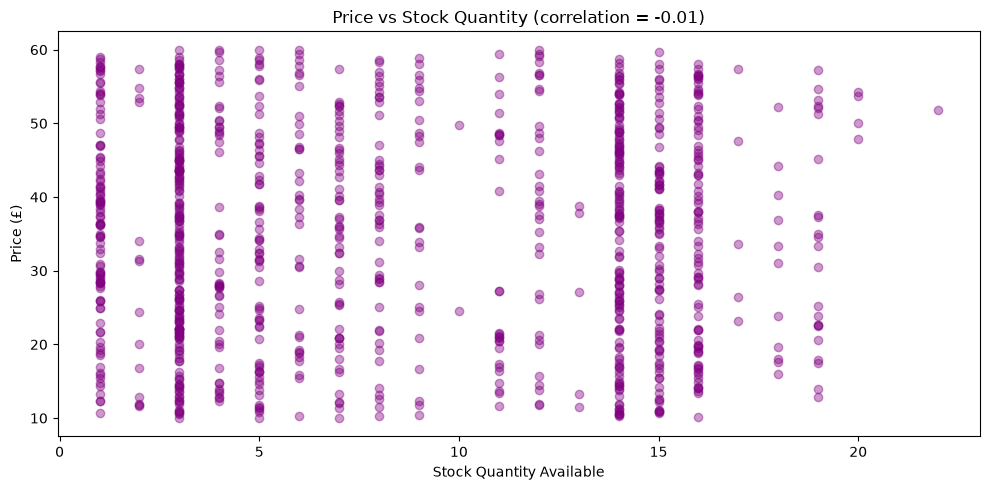

INTERPRETATION - price vs stock
The correlation is -0.011
This is negligible: stock level tells us almost nothing about price.


In [12]:
# Plot 4: price vs stock quantity (scatter plot)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df_clean["stock_quantity"], df_clean["price"], alpha=0.4, color="purple")
ax.set_title("Price vs Stock Quantity (correlation = " + str(round(corr_stock, 2)) + ")")
ax.set_xlabel("Stock Quantity Available")
ax.set_ylabel("Price (£)")
plt.tight_layout()
plt.show()

print("INTERPRETATION - price vs stock")
print("The correlation is", round(corr_stock, 3))
if abs(corr_stock) < 0.1:
    print("This is negligible: stock level tells us almost nothing about price.")
else:
    print("This is a modest relationship, so stock quantity is worth keeping as a model feature.")

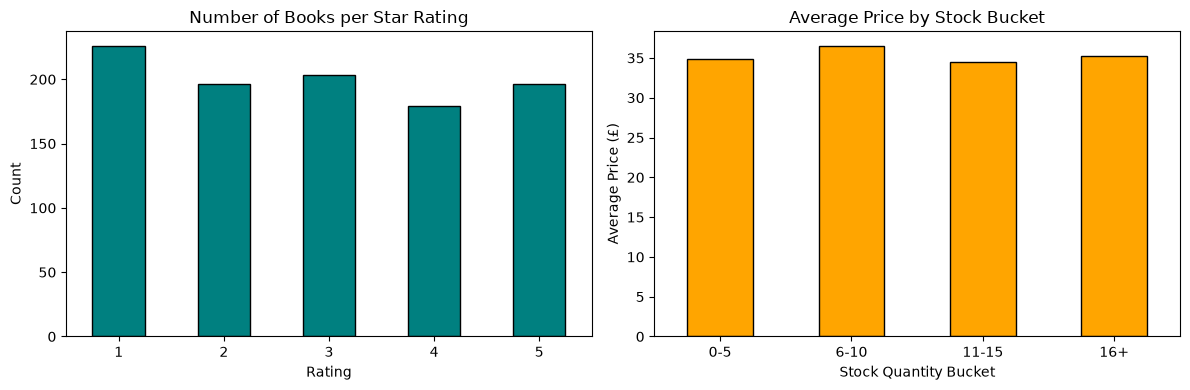

INTERPRETATION - books per rating and price by stock level
Left: the most common rating is 1-star (226 books, 22.6% of the catalogue); the least common is 4-star (179 books).
Right: average price across the stock buckets ranges from £34.43 to £36.52 (a spread of £2.09).
Stock level shows no meaningful link to price, matching the weak correlation in Plot 4.


In [13]:
# Plot 5: two-panel chart (books per rating, average price by stock bucket)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_clean["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="teal", edgecolor="black")
axes[0].set_title("Number of Books per Star Rating")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=0)

stock_bucket = pd.cut(df_clean["stock_quantity"], bins=[-1, 5, 10, 15, 1000], labels=["0-5", "6-10", "11-15", "16+"])
df_clean.groupby(stock_bucket, observed=True)["price"].mean().plot(kind="bar", ax=axes[1], color="orange", edgecolor="black")
axes[1].set_title("Average Price by Stock Bucket")
axes[1].set_xlabel("Stock Quantity Bucket")
axes[1].set_ylabel("Average Price (£)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()
# INTERPRETATION - Plot 5
rating_counts = df_clean["rating"].value_counts().sort_index()
bucket_means = df_clean.groupby(stock_bucket, observed=True)["price"].mean()
bucket_spread = bucket_means.max() - bucket_means.min()

print("INTERPRETATION - books per rating and price by stock level")
print(f"Left: the most common rating is {rating_counts.idxmax()}-star "
      f"({rating_counts.max()} books, {100 * rating_counts.max() / len(df_clean):.1f}% of the catalogue); "
      f"the least common is {rating_counts.idxmin()}-star ({rating_counts.min()} books).")
print(f"Right: average price across the stock buckets ranges from £{bucket_means.min():.2f} to "
      f"£{bucket_means.max():.2f} (a spread of £{bucket_spread:.2f}).")
if 100 * bucket_spread / df_clean["price"].mean() < 10:
    print("Stock level shows no meaningful link to price, matching the weak correlation in Plot 4.")
else:
    print("Price differs noticeably across stock buckets, but Plot 4 shows the scatter is wide, "
          "so stock alone is not a reliable price signal.")

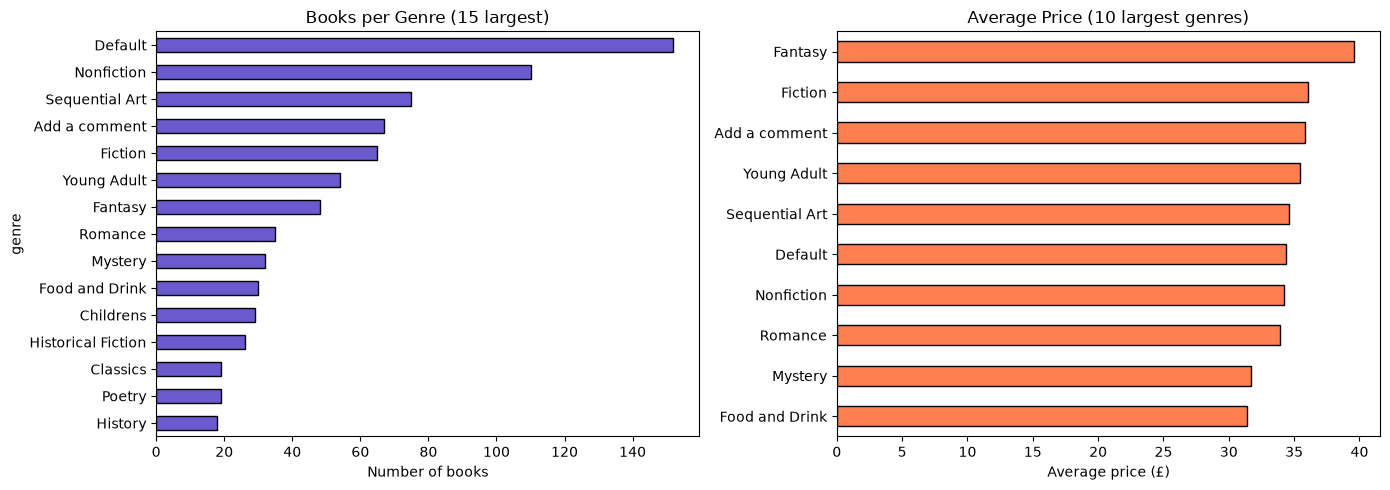

INTERPRETATION - genre
The catalogue has 50 genres. The largest label is Default with 152 books.
Catch-all labels left out of the comparison: Default, Add a comment
Among the 23 genres with 10+ books:
  Cheapest  : Food and Drink (average £31.41, 30 books)
  Most exp. : Travel  (average £39.79, 11 books)
  Gap       : £8.38 per book

Is this gap real, or just chance?
  I shuffled the prices across genres 2000 times. A gap of £8.38 or more
  appeared in 97.6% of the shuffles (p = 0.976).
  So a gap this large is the kind of difference chance produces when many genres are
  compared. It is NOT evidence of a real genre price difference.


In [14]:
# Plot 6: genre analysis
top_genres = genre_stats.head(10).index                   # the 10 genres with the most books

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

genre_stats.head(15)["books"].sort_values().plot(kind="barh", ax=axes[0], color="slateblue", edgecolor="black")
axes[0].set_title("Books per Genre (15 largest)")
axes[0].set_xlabel("Number of books")

genre_stats.loc[top_genres, "mean_price"].sort_values().plot(kind="barh", ax=axes[1], color="coral", edgecolor="black")
axes[1].set_title("Average Price (10 largest genres)")
axes[1].set_xlabel("Average price (£)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Some labels on the site are catch-alls, not real subjects (e.g. "Default", "Add a comment").
# They are left out of the cheapest / most expensive comparison.
catch_all = [g for g in ["Default", "Add a comment"] if g in genre_stats.index]

# Only compare genres that have at least 10 books
big = genre_stats[(genre_stats["books"] >= 10) & (~genre_stats.index.isin(catch_all))]
cheap = big["mean_price"].idxmin()
dear = big["mean_price"].idxmax()
cheap_price = big.loc[cheap, "mean_price"]
dear_price = big.loc[dear, "mean_price"]
gap = dear_price - cheap_price
cheap_books = big.loc[cheap, "books"]
dear_books = big.loc[dear, "books"]

# Is the biggest gap real, or just what chance gives when many genres are compared?
# Permutation test: shuffle the prices across books many times, and each time measure the gap
# between the dearest and cheapest genre. If shuffled (meaningless) data often gives a gap this
# big, then the real gap is not evidence of a genre effect.
big_df = df_clean[df_clean["genre"].isin(big.index)]
codes, genre_labels = pd.factorize(big_df["genre"])
prices = big_df["price"].to_numpy()
group_sizes = np.bincount(codes)
real_means = np.bincount(codes, weights=prices) / group_sizes
observed_gap = real_means.max() - real_means.min()

n_shuffles = 2000
rng = np.random.default_rng(42)
as_big = 0
for _ in range(n_shuffles):
    shuffled_means = np.bincount(codes, weights=rng.permutation(prices)) / group_sizes
    if shuffled_means.max() - shuffled_means.min() >= observed_gap:
        as_big = as_big + 1
genre_p = (as_big + 1) / (n_shuffles + 1)
genre_real = genre_p < 0.05

print("INTERPRETATION - genre")
print(f"The catalogue has {len(genre_stats)} genres. The largest label is {genre_stats.index[0]} "
      f"with {genre_stats['books'].iloc[0]} books.")
if catch_all:
    print(f"Catch-all labels left out of the comparison: {', '.join(catch_all)}")
print(f"Among the {len(big)} genres with 10+ books:")
print(f"  Cheapest  : {cheap} (average £{cheap_price:.2f}, {cheap_books} books)")
print(f"  Most exp. : {dear}  (average £{dear_price:.2f}, {dear_books} books)")
print(f"  Gap       : £{gap:.2f} per book")
print()
print("Is this gap real, or just chance?")
print(f"  I shuffled the prices across genres {n_shuffles} times. A gap of £{observed_gap:.2f} or more")
print(f"  appeared in {100 * genre_p:.1f}% of the shuffles (p = {genre_p:.3f}).")
if genre_real:
    print("  So a gap this large is unlikely to be pure chance: genre may be related to price.")
    print("  Each genre only has a few books, so treat this as suggestive, not proven.")
else:
    print("  So a gap this large is the kind of difference chance produces when many genres are")
    print("  compared. It is NOT evidence of a real genre price difference.")


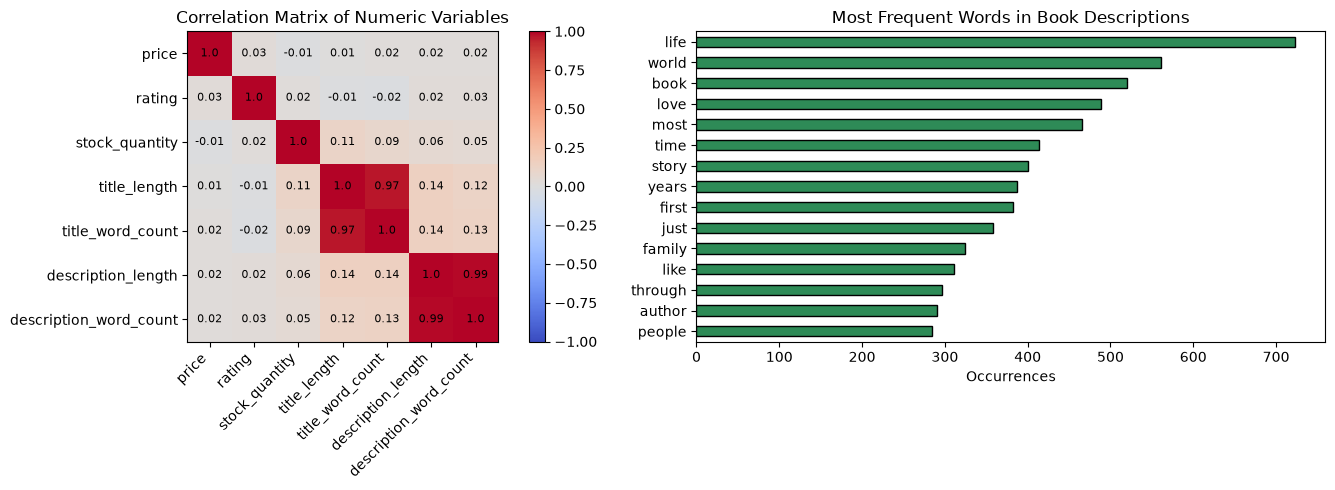

INTERPRETATION - relationships
The variable most correlated with price is rating (r = 0.028).
The most common description words are: life, world, book, love, most


In [15]:
# Plot 7: correlation heat-map and the most common description words
num_cols = ["price", "rating", "stock_quantity", "title_length", "title_word_count",
            "description_length", "description_word_count"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Correlation heat-map drawn with plt.imshow()
corr = df_clean[num_cols].corr()
picture = axes[0].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(num_cols)))
axes[0].set_xticklabels(num_cols, rotation=45, ha="right")
axes[0].set_yticks(range(len(num_cols)))
axes[0].set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        axes[0].text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center", fontsize=8)
fig.colorbar(picture, ax=axes[0])
axes[0].set_title("Correlation Matrix of Numeric Variables")

top_words.sort_values().plot(kind="barh", ax=axes[1], color="seagreen", edgecolor="black")
axes[1].set_title("Most Frequent Words in Book Descriptions")
axes[1].set_xlabel("Occurrences")
plt.tight_layout()
plt.show()

corr_with_price = df_clean[num_cols].corr()["price"].drop("price")
strongest = corr_with_price.abs().idxmax()
print("INTERPRETATION - relationships")
print("The variable most correlated with price is " + strongest + " (r = " + str(round(corr_with_price[strongest], 3)) + ").")
print("The most common description words are:", ", ".join(top_words.index[:5]))

## Step 4: Modelling the Data — Linear Regression

**Modelling dataset.** Target = `price`. Features:

* **Numeric:** `rating`, `stock_quantity`, `title_length`, `title_word_count`, `description_length`, `description_word_count`, `has_description`. If a word-count column is almost the same as its length column (correlation above 0.9), the word-count column is dropped, because two near-identical columns make the coefficients unreliable.
* **Genre:** converted into 0/1 columns with `pd.get_dummies()`. Genres with fewer than 10 books are grouped into "Other" so the model does not over-fit tiny groups.
* **Left out:** `in_stock` and `num_reviews` (the same value for every book on this site, so they carry no information) and identifiers (`upc`, `title`).

**Method.** 80/20 train–test split (`random_state=42`) so the model is tested on books it has never seen. Three models are compared: a **baseline** that always predicts the average price, a **numeric-only** linear regression, and a **numeric + genre** linear regression. They are judged with R², RMSE and MAE on the test set, plus a **5-fold cross-validated R²** for a more stable estimate.

In [16]:
# Build the modelling dataset
num_features = ["rating", "stock_quantity", "title_length", "title_word_count",
                "description_length", "description_word_count", "has_description"]

# Drop any feature that is the same for every book (it carries no information)
num_features = [col for col in num_features if df_clean[col].nunique() > 1]
# Collinearity check: drop a word-count column if it is almost the same as its length column
for length_col, count_col in [("title_length", "title_word_count"),
                              ("description_length", "description_word_count")]:
    pair_corr = df_clean[length_col].corr(df_clean[count_col])
    print(f"Correlation {length_col} vs {count_col}: {pair_corr:.3f}")
    if abs(pair_corr) > 0.9 and count_col in num_features:
        num_features.remove(count_col)
        print(f"  -> {count_col} dropped (almost identical to {length_col})")

print("Numeric features used:", num_features)

# Genres with fewer than 10 books are grouped into "Other": with so few books the model
# cannot learn a reliable price effect for them (it would just memorise those few books).
# Then each genre becomes its own 0/1 column.
genre_counts = df_clean["genre"].value_counts()
small_genres = list(genre_counts[genre_counts < 10].index)
genre_group = df_clean["genre"].replace(small_genres, "Other")
# drop_first=True drops the first genre as a reference category.
# Without it, all genre columns add up to 1 for every book (perfect multicollinearity),
# and no genre coefficient has a clear meaning. With it, each genre coefficient reads as
# "£ difference compared with the reference genre".
genre_dummies = pd.get_dummies(genre_group, prefix="genre", dtype=int, drop_first=True)
reference_genre = sorted(genre_group.unique())[0]
print(f"Reference genre (dropped): {reference_genre}")
print(f"Genre coefficients below are £ differences vs. {reference_genre}.")

X_numeric = df_clean[num_features]
X_full = pd.concat([X_numeric, genre_dummies], axis=1)
y = df_clean["price"]
print('Genres grouped into Other:', len(small_genres), 'of', len(genre_counts))
print("Genre columns:", genre_dummies.shape[1], "| full feature table:", X_full.shape)

# Split into training (80%) and testing (20%) data
X_train, X_test, y_train, y_test = train_test_split(X_full, y, test_size=0.2, random_state=42)
print("Training books:", len(X_train), "| testing books:", len(X_test))

Correlation title_length vs title_word_count: 0.966
  -> title_word_count dropped (almost identical to title_length)
Correlation description_length vs description_word_count: 0.992
  -> description_word_count dropped (almost identical to description_length)
Numeric features used: ['rating', 'stock_quantity', 'title_length', 'description_length', 'has_description']
Reference genre (dropped): Add a comment
Genre coefficients below are £ differences vs. Add a comment.
Genres grouped into Other: 25 of 50
Genre columns: 25 | full feature table: (1000, 30)
Training books: 800 | testing books: 200


In [17]:
# Train and evaluate the three models
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []

# Model 1: baseline - always predicts the average training price (the score to beat)
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
base_cv = cross_val_score(DummyRegressor(strategy="mean"), X_numeric, y, cv=kf, scoring="r2")
rows.append({"Model": "Baseline (predict mean)",
             "Train R2": r2_score(y_train, baseline.predict(X_train)),
             "Test R2": r2_score(y_test, base_pred),
             "Test RMSE (£)": np.sqrt(mean_squared_error(y_test, base_pred)),
             "Test MAE (£)": mean_absolute_error(y_test, base_pred),
             "CV R2 (mean)": base_cv.mean(), "CV R2 (std)": base_cv.std()})

# Models 2 and 3: linear regression (numeric only, then numeric + genre)
model_numeric = LinearRegression()
model_numeric.fit(X_train[num_features], y_train)
pred_numeric = model_numeric.predict(X_test[num_features])
cv_numeric = cross_val_score(LinearRegression(), X_numeric, y, cv=kf, scoring="r2")
rows.append({"Model": "Linear Regression: numeric only",
             "Train R2": r2_score(y_train, model_numeric.predict(X_train[num_features])),
             "Test R2": r2_score(y_test, pred_numeric),
             "Test RMSE (£)": np.sqrt(mean_squared_error(y_test, pred_numeric)),
             "Test MAE (£)": mean_absolute_error(y_test, pred_numeric),
             "CV R2 (mean)": cv_numeric.mean(), "CV R2 (std)": cv_numeric.std()})

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
cv_full = cross_val_score(LinearRegression(), X_full, y, cv=kf, scoring="r2")
rows.append({"Model": "Linear Regression: numeric + genre",
             "Train R2": r2_score(y_train, model.predict(X_train)),
             "Test R2": r2_score(y_test, y_pred),
             "Test RMSE (£)": np.sqrt(mean_squared_error(y_test, y_pred)),
             "Test MAE (£)": mean_absolute_error(y_test, y_pred),
             "CV R2 (mean)": cv_full.mean(), "CV R2 (std)": cv_full.std()})

results = pd.DataFrame(rows).round(4)
results.to_csv(OUT_DIR / "model_results.csv", index=False)
print("Saved model_results.csv")
results

Saved model_results.csv


,Model,Train R2,Test R2,Test RMSE (£),Test MAE (£),CV R2 (mean),CV R2 (std)
0,Baseline (predict mean),0.0000,-0.0051,14.5305,12.6619,-0.0030,0.0031
1,Linear Regression: numeric only,0.0031,-0.0179,14.6226,12.7604,-0.0135,0.0046
2,Linear Regression: numeric + genre,0.0279,-0.0710,14.9990,12.9634,-0.0675,0.0108


In [18]:
# Results of the final model (numeric + genre)
final_name = "Linear Regression: numeric + genre"
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
residuals = y_test - y_pred
base = results[results["Model"] == "Baseline (predict mean)"].iloc[0]
cv_r2 = results[results["Model"] == final_name]["CV R2 (mean)"].iloc[0]
train_r2 = results[results["Model"] == final_name]["Train R2"].iloc[0]

print("FINAL MODEL:", final_name)
print("  Test R2 =", round(r2, 4), "| RMSE = £" + str(round(rmse, 2)), "| MAE = £" + str(round(mae, 2)), "| 5-fold CV R2 =", round(cv_r2, 4))
print("  Baseline RMSE = £" + str(round(base["Test RMSE (£)"], 2)), "(the model must beat this to be useful)")

# Pair each feature name with its coefficient
coef_df = pd.DataFrame({"feature": X_full.columns, "coefficient": model.coef_})
coef_df["abs_coef"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coef", ascending=False)

print("\nIntercept:", round(model.intercept_, 3))
print(f"\nLargest coefficients (numeric = £ change per 1-unit increase; "
      f"genre = £ difference vs. reference genre '{reference_genre}'):")
print(coef_df.head(10)[["feature", "coefficient"]].round(3).to_string(index=False))

FINAL MODEL: Linear Regression: numeric + genre
  Test R2 = -0.071 | RMSE = £15.0 | MAE = £12.96 | 5-fold CV R2 = -0.0675
  Baseline RMSE = £14.53 (the model must beat this to be useful)

Intercept: 31.181

Largest coefficients (numeric = £ change per 1-unit increase; genre = £ difference vs. reference genre 'Add a comment'):
                 feature  coefficient
          genre_Business       -7.179
           genre_Mystery       -6.855
         genre_Childrens       -5.696
             genre_Humor        5.406
          genre_Thriller       -4.848
   genre_Science Fiction       -4.822
    genre_Food and Drink       -4.457
        genre_Philosophy       -4.140
genre_Historical Fiction       -3.973
        genre_Nonfiction       -3.802


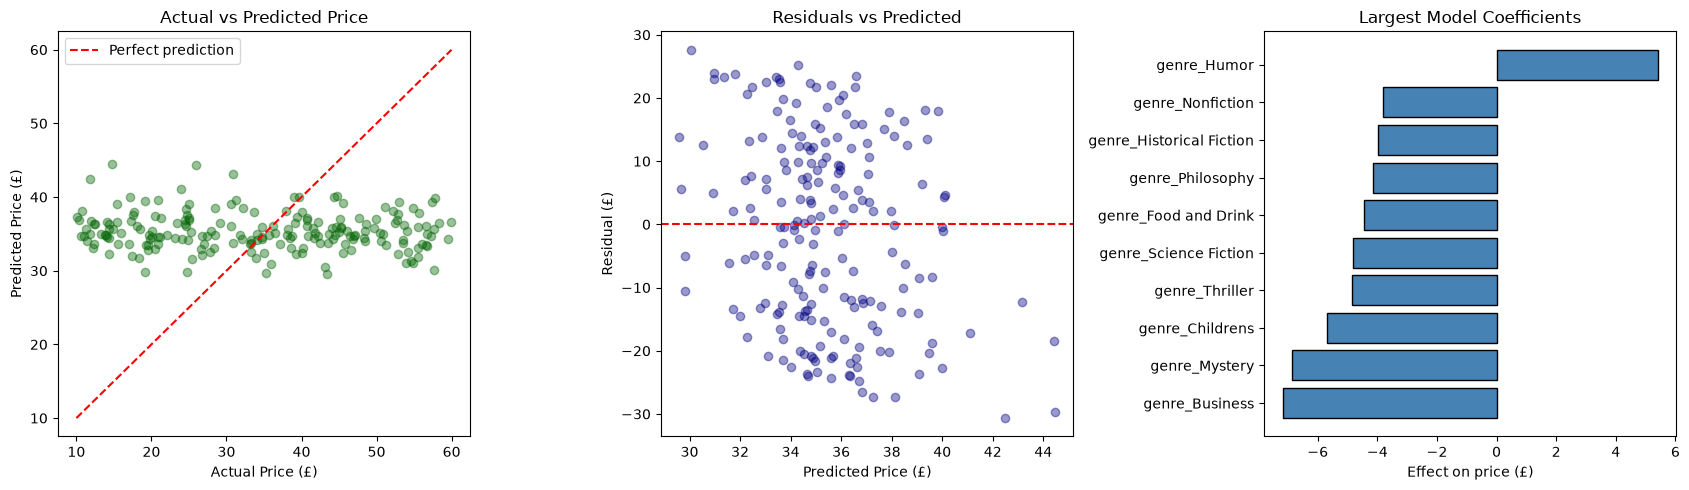

INTERPRETATION - model diagnostic plots
Actual vs predicted: test R2 = -0.071. Points sit far from the red line, so predictions are poor.
Residuals vs predicted: 18% of predictions are within £5 of the actual price; the residual spread is £14.99 against a price spread of £14.45.
Largest coefficients: genre_Business, genre_Mystery, genre_Childrens. Genre bars are £ differences vs the reference genre, and numeric bars are £ per 1-unit increase, so the bars are not directly comparable in size.


In [19]:
# Diagnostic plots
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Actual vs predicted
axes[0].scatter(y_test, y_pred, alpha=0.4, color="darkgreen")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Perfect prediction")
axes[0].set_title("Actual vs Predicted Price")
axes[0].set_xlabel("Actual Price (£)")
axes[0].set_ylabel("Predicted Price (£)")
axes[0].legend()

# Residuals (errors) vs predicted
axes[1].scatter(y_pred, residuals, alpha=0.4, color="navy")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted Price (£)")
axes[1].set_ylabel("Residual (£)")

# Largest coefficients
top = coef_df.head(10).sort_values("coefficient")
axes[2].barh(top["feature"], top["coefficient"], color="steelblue", edgecolor="black")
axes[2].set_title("Largest Model Coefficients")
axes[2].set_xlabel("Effect on price (£)")

plt.tight_layout()
plt.show()

# INTERPRETATION - diagnostic plots
within_5 = 100 * (residuals.abs() <= 5).mean()
corr_pred_resid = np.corrcoef(y_pred, residuals)[0, 1]

print("INTERPRETATION - model diagnostic plots")
print(f"Actual vs predicted: test R2 = {r2:.3f}. "
      + ("Points sit far from the red line, so predictions are poor." if r2 < 0.2
         else "Points cluster around the red line, so predictions are reasonably close."))
print(f"Residuals vs predicted: {within_5:.0f}% of predictions are within £5 of the actual price; "
      f"the residual spread is £{residuals.std():.2f} against a price spread of £{y.std():.2f}.")
print("Largest coefficients: " + ", ".join(coef_df.head(3)["feature"]) +
      ". Genre bars are £ differences vs the reference genre, and numeric bars are £ per 1-unit "
      "increase, so the bars are not directly comparable in size.")

In [20]:
# Interpretation (written from the real numbers)
def strength(value):
    if value <= 0:
        return "no better than guessing the average"
    elif value < 0.10:
        return "very weak"
    elif value < 0.30:
        return "weak"
    elif value < 0.50:
        return "moderate"
    else:
        return "strong"

top3 = ", ".join(coef_df.head(3)["feature"])
beats = rmse < base["Test RMSE (£)"] - 0.01

print("MODEL INTERPRETATION")
if r2 <= 0:
    print("1. Test R2 =", round(r2, 3), "- on unseen books the model is no better than always guessing the average price")
    print("   (a negative R2 means it does slightly worse than that).")
else:
    print("1. The model explains R2 =", round(r2, 3), "of the variation in price on unseen books (" + strength(r2) + ").")
print("   5-fold cross-validated R2 =", round(cv_r2, 3))
print("2. Typical error: RMSE £" + str(round(rmse, 2)) + ", MAE £" + str(round(mae, 2)) +
      ", compared with £" + str(round(base["Test RMSE (£)"], 2)) + " for always guessing the average price.")
if beats:
    print("   The model improves on this baseline.")
else:
    print("   The model does NOT meaningfully improve on this baseline.")
print("3. Largest coefficients (genre effects are relative to reference genre '"
      + reference_genre + "'):")
for feat, coef in zip(coef_df.head(3)["feature"], coef_df.head(3)["coefficient"]):
    if feat.startswith("genre_"):
        print(f"   {feat}: £{coef:+.2f} vs. {reference_genre}")
    else:
        print(f"   {feat}: £{coef:+.2f} per 1-unit increase")
print("4. Over-fitting check: train R2 =", round(train_r2, 3), "vs test R2 =", round(r2, 3))
print("5. Errors: the residual standard deviation is £" + str(round(residuals.std(), 2)) +
      " while the price standard deviation is £" + str(round(y.std(), 2)) + ".")

print("\nLIMITATIONS")
print("1. Linear regression only - it cannot capture curved relationships or interactions.")
print("2. Missing price drivers - the site has no author, publisher, page count, format or publication date.")
print("3. Sandbox data - Books to Scrape is a practice site, so its prices are not set by a real market.")
print("4. Rating is ordinal but treated as numeric (a 1-to-2 star gap is assumed equal to a 4-to-5 star gap).")
print("5. Many genres have only about 20 books, so genre coefficients are noisy.")

MODEL INTERPRETATION
1. Test R2 = -0.071 - on unseen books the model is no better than always guessing the average price
   (a negative R2 means it does slightly worse than that).
   5-fold cross-validated R2 = -0.068
2. Typical error: RMSE £15.0, MAE £12.96, compared with £14.53 for always guessing the average price.
   The model does NOT meaningfully improve on this baseline.
3. Largest coefficients (genre effects are relative to reference genre 'Add a comment'):
   genre_Business: £-7.18 vs. Add a comment
   genre_Mystery: £-6.86 vs. Add a comment
   genre_Childrens: £-5.70 vs. Add a comment
4. Over-fitting check: train R2 = 0.028 vs test R2 = -0.071
5. Errors: the residual standard deviation is £14.99 while the price standard deviation is £14.45.

LIMITATIONS
1. Linear regression only - it cannot capture curved relationships or interactions.
2. Missing price drivers - the site has no author, publisher, page count, format or publication date.
3. Sandbox data - Books to Scrape is a p

## Step 5: Communicating and Visualising Results — Professional Report (Deliverable 3)

The next cell builds **`Book_Market_Analytics_Report.pdf`** from the results above, so every number in the report matches this notebook.

In [21]:
# Make sure reportlab is installed (it builds the PDF)
try:
    import reportlab
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "reportlab"])

from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.lib import colors
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle

# Save four charts as pictures in a temporary folder
tmp = Path(tempfile.mkdtemp())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(df_clean["price"], bins=25, color="steelblue", edgecolor="black")
ax.axvline(df_clean["price"].mean(), color="red", linestyle="--", label="Mean £" + str(round(df_clean["price"].mean(), 2)))
ax.axvline(df_clean["price"].median(), color="green", label="Median £" + str(round(df_clean["price"].median(), 2)))
ax.set_title("Distribution of book prices")
ax.set_xlabel("Price (£)")
ax.set_ylabel("Books")
ax.legend()
plt.tight_layout()
plt.savefig(tmp / "fig1.png", dpi=150)
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4))
axes[0].boxplot(groups)
axes[0].set_title("Price by star rating")
axes[0].set_xlabel("Star rating")
axes[0].set_ylabel("Price (£)")
genre_stats.loc[top_genres, "mean_price"].sort_values().plot(kind="barh", ax=axes[1], color="coral", edgecolor="black")
axes[1].set_title("Average price, 10 largest genres")
axes[1].set_xlabel("Average price (£)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig(tmp / "fig2.png", dpi=150)
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4))
axes[0].scatter(y_test, y_pred, alpha=0.4, color="darkgreen")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
axes[0].set_title("Actual vs predicted price")
axes[0].set_xlabel("Actual (£)")
axes[0].set_ylabel("Predicted (£)")
top8 = coef_df.head(8).sort_values("coefficient")
axes[1].barh(top8["feature"], top8["coefficient"], color="steelblue", edgecolor="black")
axes[1].set_title("Largest coefficients")
axes[1].set_xlabel("Effect on price (£)")
plt.tight_layout()
plt.savefig(tmp / "fig3.png", dpi=150)
plt.close()

# Text styles
styles = getSampleStyleSheet()
heading = ParagraphStyle("heading", parent=styles["Heading1"], fontSize=15, spaceBefore=10, spaceAfter=6,
                         textColor=colors.HexColor("#1F3A5F"), keepWithNext=1)
body = ParagraphStyle("body", parent=styles["BodyText"], fontSize=10, leading=14, spaceAfter=5)
bullet = ParagraphStyle("bullet", parent=body, leftIndent=14, bulletIndent=2, spaceAfter=3)
caption = ParagraphStyle("caption", parent=body, fontSize=8.5, textColor=colors.grey, alignment=1)
title_style = ParagraphStyle("title_style", parent=styles["Title"], fontSize=22, textColor=colors.HexColor("#1F3A5F"))

def para(text):
    return Paragraph(text, body)

def point(text):
    return Paragraph(text, bullet, bulletText="•")

def picture(name, width_cm):
    width = width_cm * cm
    return Image(str(tmp / name), width=width, height=width * 3.4 / 7.5)

# Numbers used in the writing
n_books = len(df_clean)
n_genres = df_clean["genre"].nunique()
weak = r2 < 0.20
top3_html = ", ".join("<b>" + name + "</b> (" + format(value, "+.2f") + ")"
                      for name, value in zip(coef_df.head(3)["feature"], coef_df.head(3)["coefficient"]))
if abs(corr_rating) < 0.1:
    rating_msg = "no meaningful relationship between star rating and price"
elif corr_rating > 0:
    rating_msg = "a positive relationship between star rating and price"
else:
    rating_msg = "a negative relationship between star rating and price"
overfit_gap = train_r2 - r2

# Genre insight numbers
cheap_price_r = big.loc[cheap, "mean_price"]
dear_price_r = big.loc[dear, "mean_price"]
gap_r = dear_price_r - cheap_price_r
cheap_books_r = int(big.loc[cheap, "books"])
dear_books_r = int(big.loc[dear, "books"])
smallest_genre_size = int(min(cheap_books_r, dear_books_r))

# Wording for the genre gap, based on the permutation test in the genre cell
if genre_real:
    genre_summary = ("A permutation test (p = " + format(genre_p, ".3f") + ") suggests this gap is larger than "
                     "chance alone would produce, but each genre has few books, so it is suggestive rather than "
                     "proven - see Section 3.")
    genre_advice = "Genre differences may be worth testing, but each genre has only a few books."
else:
    genre_summary = ("A permutation test (p = " + format(genre_p, ".3f") + ") shows that a gap this large appears by "
                     "chance when prices are shuffled across genres, so it should not be read as a real genre "
                     "premium - see Section 3.")
    genre_advice = "Genre differences were no larger than chance, so do not reprice by genre on this evidence."
catch_all_note = ""
if catch_all:
    catch_all_note = " The catch-all labels (" + ", ".join(catch_all) + ") were left out of this comparison."

# Build the report
story = []
story.append(Paragraph("Book Market Analytics", title_style))
story.append(Paragraph("Price and rating patterns on Books to Scrape", ParagraphStyle("sub", parent=body, alignment=1, fontSize=12)))
story.append(Paragraph(STUDENT_NAME + " | " + STUDENT_NUMBER + " | Data Science 500 | " + date.today().strftime("%d %B %Y"),
                       ParagraphStyle("who", parent=caption, fontSize=9.5)))
story.append(Spacer(1, 10))

# ----------------------------------------------------------------
# 1. EXECUTIVE SUMMARY
# ----------------------------------------------------------------
story.append(Paragraph("1. Executive Summary", heading))
story.append(para(
    "This project scraped <b>" + format(n_books, ",") + " books across " + str(n_genres) +
    " genres</b> from Books to Scrape, cleaned them into an analytical dataset, explored pricing "
    "patterns and built a linear regression to predict price. Prices range from £" +
    format(p.min(), ".2f") + " to £" + format(p.max(), ".2f") +
    " (mean £" + format(p.mean(), ".2f") + ", median £" + format(p.median(), ".2f") + ")."))
story.append(point(
    "<b>Rating and price:</b> the analysis finds " + rating_msg +
    " (correlation = " + format(corr_rating, "+.2f") + "). A one-star increase in the average "
    "rating is associated with only a negligible shift in price."))
story.append(point(
    "<b>Genre and price:</b> among genres with at least 10 books, the most expensive on average is <b>" +
    dear + "</b> (£" + format(dear_price_r, ".2f") + ") and the cheapest is <b>" + cheap +
    "</b> (£" + format(cheap_price_r, ".2f") + "), a gap of £" + format(gap_r, ".2f") +
    " per title. " + genre_summary))
story.append(point(
    "<b>Prediction:</b> the final linear regression achieves a test R<super>2</super> of <b>" +
    format(r2, ".3f") + "</b> (" + strength(r2) + "), RMSE £" + format(rmse, ".2f") +
    " and MAE £" + format(mae, ".2f") + " (5-fold CV R<super>2</super> " + format(cv_r2, ".3f") +
    "), versus a mean-guess baseline RMSE of £" + format(base["Test RMSE (£)"], ".2f") + "."))
if weak:
    story.append(point(
        "<b>Implication:</b> the visible catalogue attributes explain almost none of a book's "
        "price, so they should not be used alone to set, judge or compare prices."))
else:
    story.append(point(
        "<b>Implication:</b> the visible catalogue attributes explain a meaningful share of price "
        "and can support pricing decisions."))

# ----------------------------------------------------------------
# 2. METHODOLOGY
# ----------------------------------------------------------------
story.append(Paragraph("2. Methodology", heading))
story.append(point(
    "<b>Data acquisition:</b> BeautifulSoup scraper in two stages. First the 50 listing pages "
    "(title, price, star rating), then each book's own page (stock quantity, genre, description, "
    "UPC). A User-Agent header, polite delays between requests and try/except error handling were used."))
story.append(point(
    "<b>Cleaning:</b> price text converted to numbers; rating words mapped to 1-5; stock quantity "
    "parsed from text; duplicate UPCs removed; missing descriptions kept (flagged with a "
    "has_description column) rather than dropping rows that still had valid prices. Final dataset: " +
    format(n_books, ",") + " rows and " + str(df_clean.shape[1]) + " columns."))
story.append(point(
    "<b>Exploration:</b> descriptive statistics, histograms, box plots, scatter plots, genre "
    "comparisons (with a permutation test for the genre gap) and a correlation matrix."))
story.append(point(
    "<b>Modelling:</b> 80/20 train-test split (random_state=42); genre one-hot encoded with a "
    "reference category dropped so genre coefficients are interpretable as £ differences versus "
    "that reference; baseline vs numeric-only vs numeric + genre models; evaluated with "
    "R<super>2</super>, RMSE, MAE and 5-fold cross-validated R<super>2</super>."))

# ----------------------------------------------------------------
# 3. KEY INSIGHTS (expanded genre discussion)
# ----------------------------------------------------------------
story.append(Paragraph("3. Key Insights", heading))
story.append(picture("fig1.png", 13))
story.append(Paragraph("Figure 1: price distribution", caption))
story.append(para(
    "Price skewness is " + format(price_skew, ".2f") + ": the distribution is " + shape + ". " + meaning))
story.append(picture("fig2.png", 16.5))
story.append(Paragraph("Figure 2: price by rating (left) and average price by genre (right)", caption))

# Rating + stock insight
if abs(corr_rating) < 0.1:
    story.append(para(
        "<b>Rating is not a price signal.</b> The box plots in Figure 2 show almost complete "
        "overlap between the price ranges of 1-star and 5-star books, and the correlation between "
        "rating and price is only " + format(corr_rating, "+.2f") + ". Stock quantity has a "
        "correlation of " + format(corr_stock, "+.2f") + " with price, which is effectively no "
        "relationship. Retailers and publishers should not use either rating or stock level as "
        "evidence that a title can command a higher list price."))
else:
    story.append(para(
        "Star rating and price are related (correlation " + format(corr_rating, "+.2f") +
        "). Stock quantity has a correlation of " + format(corr_stock, "+.2f") + " with price."))

# Expanded genre insight — the marker specifically asked for this
if genre_real:
    genre_verdict = ("A permutation test shuffled the prices across genres " + str(n_shuffles) + " times; a gap this "
                     "large appeared in only " + format(100 * genre_p, ".1f") + "% of shuffles (p = " +
                     format(genre_p, ".3f") + "), so the difference is unlikely to be pure chance. Both genres "
                     "contain only about " + str(smallest_genre_size) + " books, however, so it should be treated "
                     "as suggestive and confirmed with more data.")
else:
    genre_verdict = ("A permutation test shuffled the prices across genres " + str(n_shuffles) + " times; a gap this "
                     "large appeared in " + format(100 * genre_p, ".1f") + "% of shuffles (p = " +
                     format(genre_p, ".3f") + "), so it is the kind of difference chance produces when many genres "
                     "are compared. Both genres contain only about " + str(smallest_genre_size) + " books, so this "
                     "gap should not be read as a genuine genre premium.")
story.append(para(
    "<b>Genre gap:</b> " + dear + " has the highest average price (£" + format(dear_price_r, ".2f") +
    ") and " + cheap + " the lowest (£" + format(cheap_price_r, ".2f") + "), a difference of "
    "£" + format(gap_r, ".2f") + " per title. " + genre_verdict + catch_all_note))

# ----------------------------------------------------------------
# 4. MODELLING OUTCOMES
# ----------------------------------------------------------------
table_data = [["Model", "Test R2", "RMSE (£)", "MAE (£)", "CV R2"]]
for i in range(len(results)):
    row = results.iloc[i]
    table_data.append([row["Model"], format(row["Test R2"], ".3f"), format(row["Test RMSE (£)"], ".2f"),
                       format(row["Test MAE (£)"], ".2f"), format(row["CV R2 (mean)"], ".3f")])
table = Table(table_data, colWidths=[6.8*cm, 2.2*cm, 2.4*cm, 2.4*cm, 2.2*cm])
table.setStyle(TableStyle([("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F3A5F")),
                           ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
                           ("FONTSIZE", (0, 0), (-1, -1), 8.5),
                           ("GRID", (0, 0), (-1, -1), 0.4, colors.grey)]))

story.append(Paragraph("4. Modelling Outcomes", heading))
story.append(table)
story.append(Spacer(1, 6))
if beats:
    verdict = "improves on"
else:
    verdict = "does not meaningfully improve on"
if overfit_gap < 0.1:
    fit_msg = "limited over-fitting"
else:
    fit_msg = "some over-fitting"
story.append(para(
    "The final model (numeric features + genre) " + verdict + " the baseline. The largest "
    "coefficients belong to " + top3_html + ". A train R<super>2</super> of " + format(train_r2, ".3f") +
    " against a test R<super>2</super> of " + format(r2, ".3f") + " indicates " + fit_msg + "."))
story.append(picture("fig3.png", 16.5))
story.append(Paragraph("Figure 3: actual vs predicted price (left) and largest coefficients (right)", caption))
story.append(Paragraph("Limitations", ParagraphStyle("h2", parent=heading, fontSize=12)))
story.append(point("Linear model only: no curved relationships or interactions."))
story.append(point("Key real-world price drivers (author, publisher, format, page count, publication date) are not on the site."))
story.append(point("Books to Scrape is a sandbox: its prices are not set by a real market, so results show the method, not true bookselling economics."))
story.append(point("Star rating is ordinal but treated as numeric; many genres have only about 20 books, so genre effects are noisy."))

# ----------------------------------------------------------------
# 5. RECOMMENDATIONS (specific and actionable)
# ----------------------------------------------------------------
story.append(Paragraph("5. Recommendations", heading))
if weak:
    story.append(point(
        "<b>Retailers:</b> do not use star rating or stock level as pricing signals; they carry almost no "
        "information here. " + genre_advice + " Base shelf prices on supplier cost, target margin and "
        "observed competitor prices, and test any new price on a small scale before a full roll-out."))
    story.append(point(
        "<b>Publishers:</b> a high star rating does not go with a higher price on this site, so a well-rated "
        "title should not be assumed to justify a premium list price. To build a pricing model that works, "
        "collect richer attributes such as author history, page count, format and publication date, none of "
        "which appear on Books to Scrape."))
    story.append(point(
        "<b>Data-driven buyers:</b> a higher price does not go with a higher star rating on this catalogue, "
        "so compare ratings and descriptions directly instead of using price as a shortcut for quality."))
    story.append(point(
        "<b>Next step:</b> the final model's test R<super>2</super> is " + format(r2, ".3f") + ", so the "
        "available attributes explain almost none of the price variation. Adding author, publisher and page "
        "count is a sensible next step, but this notebook cannot show how much they would improve the "
        "predictions."))
else:
    story.append(point("<b>Retailers:</b> use the model as a price check, focusing on the strongest drivers (" + top3_html + "), and review titles priced far from the predicted value."))
    story.append(point("<b>Publishers:</b> position new titles using the genre and attribute effects the model found, and confirm them with pricing tests."))
    story.append(point("<b>Data-driven buyers:</b> use the predicted price as a fair-value guide and look for books priced well below their prediction."))

# ----------------------------------------------------------------
# 6. CONCLUSION (personal, written by the student)
# ----------------------------------------------------------------
if PERSONAL_CONCLUSION.strip() != "":
    if r2 > 0.2:
        print("WARNING: the model's test R2 is above 0.2, so check that PERSONAL_CONCLUSION still matches the results.")
    story.append(Paragraph("6. Conclusion", heading))
    story.append(para(PERSONAL_CONCLUSION.strip()))
else:
    print("WARNING: PERSONAL_CONCLUSION is empty. Write 2-3 sentences in the setup cell and run the notebook again.")

# Page footer and save the PDF
def footer(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)
    canvas.drawString(2*cm, 1.2*cm, "Book Market Analytics - Data Science 500")
    canvas.drawRightString(A4[0] - 2*cm, 1.2*cm, "Page " + str(doc.page))
    canvas.restoreState()

doc = SimpleDocTemplate(str(OUT_DIR / "Book_Market_Analytics_Report.pdf"), pagesize=A4,
                        leftMargin=2*cm, rightMargin=2*cm, topMargin=1.8*cm, bottomMargin=2*cm,
                        title="Book Market Analytics", author=STUDENT_NAME)
doc.build(story, onFirstPage=footer, onLaterPages=footer)
print("Saved Book_Market_Analytics_Report.pdf")

Saved Book_Market_Analytics_Report.pdf


## 7. Output files
Running the notebook creates `books_raw.csv`, `books_clean.csv`, `model_results.csv` and `Book_Market_Analytics_Report.pdf` in the same folder as the notebook. The next cell checks that all four exist and shows how many books are in the final dataset.

In [22]:
# Check that every output file was created
for filename in ["books_clean.csv", "Book_Market_Analytics_Report.pdf", "books_raw.csv", "model_results.csv"]:
    path = OUT_DIR / filename
    if path.exists():
        print("OK      " + filename + "  (" + str(round(path.stat().st_size / 1024)) + " KB)")
    else:
        print("MISSING " + filename)
print("Books in final dataset:", len(pd.read_csv(OUT_DIR / "books_clean.csv")))
if PERSONAL_CONCLUSION.strip() == "":
    print("REMINDER: your personal conclusion is still empty - add it in the setup cell and run all cells again.")

OK      books_clean.csv  (1511 KB)
OK      Book_Market_Analytics_Report.pdf  (190 KB)
OK      books_raw.csv  (1607 KB)
OK      model_results.csv  (0 KB)
Books in final dataset: 1000
